In [1]:
# This is a companion notebook to "Oracle-centric perspective on structured quantum search applied
# to lattice sieving" (Kavalaris, Mardiris, Karafyllidis).
# This companion runs either on Jupyter Notebook or Google Colab.
# It needs Qiskit to be installed. It was tested with Qiskit 2.6.1.

# In this example, the sieving predicate is realized as a global oracle, a phase inversion over the
# space of candidate pairs, composed with the Grover diffusion as described in Section 4 of the
# paper. A small sieve list is built, its reducible pairs are found, and Grover search over the
# candidate pairs is run with and without the oracle, first on a simulator and then, optionally, on
# IBM hardware.

In [2]:
# The line below is used the first time to install Qiskit and pylatexenc if they are not already
# installed. pylatexenc is used by Qiskit to draw circuits. The line is commented out, so if you do
# not have these libraries installed, remove the # from the line below. This is definitely needed
# in Google Colab.

# %pip install qiskit pylatexenc

In [3]:
# Load the needed libraries

import itertools
import math
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler

# Needed in Jupyter notebooks so that plots appear below the cells that create them
%matplotlib inline 

# Print the used versions. This example was created with Qiskit 2.6.1 and numpy 2.4.6.
print("qiskit", qiskit.__version__, "| numpy", np.__version__)

qiskit 2.6.1 | numpy 2.4.6


In [4]:
# Some explanation on the sieve list, the sieving predicate and the search space

# Sieve list. A lattice sieve keeps a list of lattice vectors and repeatedly looks for pairs that
# can be combined into a shorter vector (as described in Section 2.2 of the paper).
# At a given iteration the vectors in the list have roughly the same length. To mimic one such
# iteration, six vectors L_list = {v1, ..., v6} of the lattice Z^10 are drawn at random, with
# coordinates in -3..3, and a vector is kept only if its squared norm lies within 2 of 40,
# so that all of them lie in one thin norm shell. Vectors equal up to sign are rejected,
# because v and -v always form a trivial reducible pair, since v + (-v) = 0, which is not useful
# in a sieve. Real sieves use far larger lists in much higher dimensions.
# The example uses only six vectors so that the quantum circuit stays small enough to simulate.


# Predicate. A pair (v_i, v_j) is reducible when Eq. (11) holds,
# ||v_i - v_j|| < max(||v_i||, ||v_j||)   or   ||v_i + v_j|| < max(||v_i||, ||v_j||),
# that is, when their difference or their sum is shorter than the longer of the two, so that
# replacing the longer vector by v_i - v_j or v_i + v_j puts a shorter vector into the list. For
# vectors of nearly equal length this is essentially an angle condition. The angle between v_i and
# v_j is below 60 degrees (difference shorter) or above 120 degrees (sum shorter). This is the
# predicate f of Eq. (12). The set of reducible pairs is the marked set M = f^-1(1) of Eq. (14). The
# truth table of f is computed here classically, and the Grover oracle in the following cells is
# built from it.

# Search space. The 15 unordered pairs (v_i, v_j), i < j, are the candidates of the Grover
# realization (Section 4). They are indexed 0..14 in lexicographic order, so that (v1, v2) = 0,
# (v1, v3) = 1, ..., (v5, v6) = 14.

In [5]:
# The example uses a small sieve list of lattice vectors, so that the search over its candidate
# pairs fits into a few qubits. These are the initial parameters of the sieving instance.

SEED = 20251006
# This is a seed of NumPy's pseudo-random number generator. It is fixed so that every run gives the
# same list. The same seed always produces the same random numbers, so every reader obtains exactly
# the instance and the results reported in the paper. The value of SEED is arbitrary (it is a date
# written as an integer). Readers may change SEED to obtain other instances. A seed whose list
# contains no reducible pair leaves nothing to search for. In such a case, the example stops with a
# message asking for another seed.

DIM = 10
# Dimension of the lattice Z^DIM from which the vectors are drawn. The vectors belong to the integer
# lattice Z^DIM, the simplest lattice of dimension DIM.
# Why Z^10? Z^10 is used for simplicity. Every integer vector is a lattice vector, so no lattice
# basis is needed, and all squared norms are exact integers, so the predicate is decided exactly.
# The example models one pair-search step of a sieve, not an attack on a cryptographic lattice.
# Why dimension 10? Two vectors of similar length form a reducible pair only if the angle between
# them is below 60 or above 120 degrees, and random vectors in higher dimensions tend to be close to
# orthogonal (see Ref. [5] of the paper). So only a few of the 15 pairs of a list are reducible, and
# the marked set is sparse, as in a real sieve. The check "HOW COMMON IS THE NUMBER OF REDUCIBLE
# PAIRS OF THE EXAMPLE LIST?" further below shows this for 300 lists of this kind.

LIST_SIZE = 6
# Number of vectors in the sieve list L_list = {v1, ..., v6}. It fixes the size of the search space
# at 6 * 5 / 2 = 15 unordered pairs (each of the 6 vectors with each of the other 5, divided by 2
# because (v_i, v_j) and (v_j, v_i) are the same pair), whose indices 0..14 fit on 4 qubits
# (index 15 is an unused padding state).

COORD_RANGE = 3
# Each coordinate is drawn uniformly from the integers -3, -2, ..., 3.
# Small integers keep the vectors readable and all norms exact.

NORM2_TARGET = 4 * DIM
# Centre of the norm shell, in squared norm (= 40). A coordinate drawn uniformly from -3..3
# has mean square (0 + 2*1 + 2*4 + 2*9) / 7 = 4, so a random vector has mean squared norm 4 * DIM.
# Centring the shell on this value keeps the largest share of the random draws.
# Note that the factor 4 holds only for COORD_RANGE = 3. For a range -r..r the mean square per
# coordinate is r * (r + 1) / 3.

NORM2_WIDTH = 2
# Half-width of the norm shell. A vector is kept only if | ||v||^2 - NORM2_TARGET | <= NORM2_WIDTH,
# i.e. ||v||^2 in 38..42. The norms then lie between sqrt(38) = 6.16 and sqrt(42) = 6.48, within
# about 5% of each other, as in one sieve iteration, where all list vectors have nearly the same
# length.

NUM_CHECK_LISTS = 300
# Number of comparison lists used in the check "HOW COMMON IS THE NUMBER OF REDUCIBLE PAIRS OF THE
# EXAMPLE LIST?" further below. The check is needed because the result of the Grover search depends
# on how many pairs of the list are reducible (the size of the marked set). Each comparison list is
# built exactly like the example list (same DIM, LIST_SIZE, COORD_RANGE and norm shell), but from a
# different seed, SEED + 1, SEED + 2, ..., SEED + NUM_CHECK_LISTS, so the comparison lists are also
# reproducible. The check counts the reducible pairs in every comparison list and prints how often
# each count occurs, so that the reader can see whether the count of the example list is a common
# or an unusual one. 300 lists are enough for the frequencies to be clearly visible and few enough
# for the check to run quickly.

In [6]:
# Necessary functions.
# This cell only defines functions and computes nothing yet. The functions use the parameters of
# the previous cell, so the example list and the comparison lists of the check "HOW COMMON IS
# THE NUMBER OF REDUCIBLE PAIRS OF THE EXAMPLE LIST?" are built by exactly the same code.

# The function sieve_list(seed) returns a random sieve list of LIST_SIZE vectors of Z^DIM.
# Each coordinate is drawn uniformly from -COORD_RANGE..COORD_RANGE. A vector
# is kept only if its squared norm lies in the norm shell
# NORM2_TARGET - NORM2_WIDTH .. NORM2_TARGET + NORM2_WIDTH, and only if neither it nor its
# negative is already in the list (v and -v would form a trivially reducible pair,
# since v + (-v) = 0). Vectors are drawn until LIST_SIZE of them have been kept.
# The random numbers come from NumPy's generator started with `seed`, drawn as 64-bit integers,
# so the same seed gives the same list on every computer.
def sieve_list(seed):
    rng = np.random.default_rng(seed)
    vectors = []
    while len(vectors) < LIST_SIZE:
        v = rng.integers(-COORD_RANGE, COORD_RANGE + 1, size=DIM, dtype=np.int64)
        if abs(int(v @ v) - NORM2_TARGET) > NORM2_WIDTH:
            continue                        # outside the norm shell
        if any((v == u).all() or (v == -u).all() for u in vectors):
            continue                        # already in the list, up to sign
        vectors.append(v)
    return vectors

# The function is_reducible(u, w) returns True if u - w or u + w is shorter than the longer
# of u and w, and False otherwise. This is the sieving predicate of Eq. (11).
# The comparison uses squared norms, which are exact integers, so no rounding occurs.
def is_reducible(u, w):
    longest2 = max(int(u @ u), int(w @ w))
    return int((u - w) @ (u - w)) < longest2 or int((u + w) @ (u + w)) < longest2
# longest2 means longest^2 (squared)

# The function candidate_pairs() returns the search space, i.e. all unordered pairs (i, j), i < j,
# of positions in the list, in lexicographic order. Positions are 0-based in the code, so the pair
# (0, 1) is (v1, v2) in the notation of the paper and has index 0.
def candidate_pairs():
    return list(itertools.combinations(range(LIST_SIZE), 2))


# The function marked_pairs(vectors) returns the marked set M = f^-1(1) of Eq. (14), i.e. the
# indices (into candidate_pairs()) of the pairs that satisfy the predicate. This is the classical
# truth table of f from which the Grover oracle is built.
def marked_pairs(vectors):
    return [k for k, (i, j) in enumerate(candidate_pairs())
            if is_reducible(vectors[i], vectors[j])]


# The function pair_label(k) returns the pair with index k written as in the paper,
# e.g. 13 -> '(v4, v6)'.
def pair_label(k):
    i, j = candidate_pairs()[k]
    return f"(v{i + 1}, v{j + 1})"

In [7]:
# This cell builds the sieve list of the example with SEED, evaluates the sieving predicate on all
# 15 candidate pairs and prints the result. For every reducible pair it also shows which of the two
# conditions of Eq. (11) holds, i.e. whether the difference v_i - v_j or the sum v_i + v_j is
# shorter than the longer of the two vectors. Squared norms are printed, because they are exact
# integers.

vectors = sieve_list(SEED)
pairs = candidate_pairs()
M = marked_pairs(vectors)

# If the list has no reducible pair there is nothing to search for, so the example stops here
# with an explanation instead of failing later.
if len(M) == 0:
    raise SystemExit("This seed gives no reducible pair, so there is nothing "
                     "to search for. Please choose another SEED.")

print(f"Sieve list: {LIST_SIZE} vectors of Z^{DIM} (SEED = {SEED})")
for i, v in enumerate(vectors):
    print(f"  v{i + 1} = {tuple(int(c) for c in v)}   ||v{i + 1}||^2 = {int(v @ v)}")

print(f"\n{len(pairs)} candidate pairs; reducible pairs (marked set M):")
for k in M:
    i, j = pairs[k]
    longest2 = max(int(vectors[i] @ vectors[i]), int(vectors[j] @ vectors[j]))
    diff2 = int((vectors[i] - vectors[j]) @ (vectors[i] - vectors[j]))
    sum2 = int((vectors[i] + vectors[j]) @ (vectors[i] + vectors[j]))
    if diff2 < longest2:
        reason = f"||v{i + 1} - v{j + 1}||^2 = {diff2}"
    else:
        reason = f"||v{i + 1} + v{j + 1}||^2 = {sum2}"
    print(f"  index {k}: {pair_label(k)}, {reason} < {longest2} = larger squared norm")
print(f"\n|M| = {len(M)} marked pairs out of {len(pairs)}")
# sum2 means sum^2 and diff2 means diff^2.

Sieve list: 6 vectors of Z^10 (SEED = 20251006)
  v1 = (-3, -3, -1, 0, 3, 0, -3, -2, -1, 0)   ||v1||^2 = 42
  v2 = (3, -2, 1, 0, 3, 0, 2, 2, 0, 3)   ||v2||^2 = 40
  v3 = (2, -1, 2, 2, -3, 0, 2, -3, 1, -2)   ||v3||^2 = 40
  v4 = (3, 2, 1, -1, 0, -3, -1, 3, -2, 1)   ||v4||^2 = 39
  v5 = (-2, -2, 2, -3, -3, 1, 0, -3, 0, -1)   ||v5||^2 = 41
  v6 = (-3, -1, 3, 0, -1, 3, 3, -1, 1, 1)   ||v6||^2 = 41

15 candidate pairs; reducible pairs (marked set M):
  index 13: (v4, v6), ||v4 + v6||^2 = 32 < 41 = larger squared norm
  index 14: (v5, v6), ||v5 - v6||^2 = 38 < 41 = larger squared norm

|M| = 2 marked pairs out of 15


In [8]:
# This cell answers the question "HOW COMMON IS THE NUMBER OF REDUCIBLE PAIRS OF THE EXAMPLE LIST?"
# that was mentioned in the comments above.
# The given example list has len(M) reducible pairs (two for SEED = 20251006).
# This check shows whether that number is a common or an unusual outcome for lists of this kind.
# NUM_CHECK_LISTS = 300 comparison lists are built with the same functions as the example list, from
# the seeds SEED + 1, SEED + 2, ..., SEED + 300, and the reducible pairs of each list are counted.
# The cell prints how many lists have 0, 1, 2, ... reducible pairs, and marks the count of the
# example list with an arrow.

counts = np.array([len(marked_pairs(sieve_list(SEED + k)))
                   for k in range(1, NUM_CHECK_LISTS + 1)])

values, frequencies = np.unique(counts, return_counts=True)
print(f"Reducible pairs in {NUM_CHECK_LISTS} comparison lists:")
for value, frequency in zip(values, frequencies):
    marker = "   <- example list" if value == len(M) else ""
    print(f"  {value} reducible pairs: {frequency:3d} lists  "
          f"{'#' * (frequency // 4)}{marker}")

num_pairs = len(candidate_pairs())
print(f"\nmean: {counts.mean():.2f} reducible pairs out of {num_pairs}")
print(f"lists with the same count as the example list ({len(M)}): "
      f"{np.sum(counts == len(M))} of {NUM_CHECK_LISTS}")
print(f"lists with one or two reducible pairs: "
      f"{np.mean((counts == 1) | (counts == 2)):.0%}")

Reducible pairs in 300 comparison lists:
  0 reducible pairs:  37 lists  #########
  1 reducible pairs:  81 lists  ####################
  2 reducible pairs: 102 lists  #########################   <- example list
  3 reducible pairs:  37 lists  #########
  4 reducible pairs:  31 lists  #######
  5 reducible pairs:  10 lists  ##
  6 reducible pairs:   1 lists  
  9 reducible pairs:   1 lists  

mean: 1.95 reducible pairs out of 15
lists with the same count as the example list (2): 102 of 300
lists with one or two reducible pairs: 61%


In [9]:
# Reading the result. For SEED = 20251006, two reducible pairs is the most frequent count
# (102 of the 300 lists), and most lists have one or two, so the example list is not an unusual
# case. The small numbers reflect the high-dimensional geometry described above. Random vectors
# tend to be close to orthogonal, so few pairs satisfy Eq. (11), and the marked set is sparse.

# For SEED = 20251006, the output shows a mean of 1.95 reducible pairs out of 15,
# two reducible pairs in 102 of the 300 lists and one or two in 61% of them.

In [10]:
# This cell defines the functions and parameters for the Grover algorithm realization
# and as previously nothing is computed yet. These functions build the Grover search
# of Section 4 of the paper over the candidate pairs.

#     oracle      O_f = I - 2 * sum over x in M of |x><x|     (Eq. (12))
#     diffusion   D   = 2|s><s| - I, with |s> = H^n |0...0>
#     iteration   G   = D O_f                                   (Eq. (8))

# Encoding. The pair index x = 0..14 is stored in binary on N_QUBITS = 4 qubits, since 2^4 = 16
# is the smallest power of two that holds 15 indices. The extra index 15 corresponds to no pair.
# It is never marked and only enlarges the search space from 15 to N = 16 states.
# Qiskit numbers qubits from the least significant bit, so bit q of x is stored on qubit q.

# Oracle. The predicate f has already been evaluated classically for every pair
# (the marked set M of Cell 7). The oracle is built from this truth table.
# For each marked index it flips the sign of that one basis state.
# A quantum oracle that evaluates the vector norms itself, in superposition, would act in the
# same way on the pair register, but it requires additional arithmetic circuits and is outside
# the scope of this example.
N_QUBITS = math.ceil(math.log2(len(candidate_pairs())))     # = 4

# The function phase_flip_on_basis_state(qc, index, n) multiplies the basis state |index> of
# an n-qubit register by -1 and leaves every other basis state unchanged. A multi-controlled phase
# gate P(pi) flips the sign of |1...1> only. X gates applied before and after it, on the qubits
# where `index` has a 0 bit, move that sign flip from |1...1> to |index>.
def phase_flip_on_basis_state(qc, index, n):
    zeros = [q for q in range(n) if not (index >> q) & 1]
    if zeros:
        qc.x(zeros)
    qc.mcp(np.pi, list(range(n - 1)), n - 1)
    if zeros:
        qc.x(zeros)

# The function grover_oracle(qc, marked) applies O_f, with one sign flip for each marked pair
# index, so that O_f |x> = -|x> if x is in M and |x> otherwise.
def grover_oracle(qc, marked, n=N_QUBITS):
    for m in marked:
        phase_flip_on_basis_state(qc, m, n)

# The function grover_diffusion(qc) applies the diffusion operator. Since
#    2|s><s| - I = H^n (2|0...0><0...0| - I) H^n, it is built as Hadamard gates,
# a sign flip of |0...0>, and Hadamard gates again. This realizes D up to an overall factor -1
# (a global phase), which has no effect on any measured probability.
def grover_diffusion(qc, n=N_QUBITS):
    qc.h(range(n))
    phase_flip_on_basis_state(qc, 0, n)
    qc.h(range(n))

# The function optimal_iterations(N, num_marked) returns the number of Grover iterations that
# maximizes the probability of measuring a marked state,
# k = floor(pi / (4 theta)) with sin(theta) = sqrt(num_marked / N) [2].
def optimal_iterations(N, num_marked):
    theta = math.asin(math.sqrt(num_marked / N))
    return math.floor(math.pi / (4 * theta))

# The function grover_circuit(marked, iterations, use_oracle, measure) builds the full circuit,
# made of Hadamard gates that prepare |s>, followed by `iterations` Grover iterations. With
# use_oracle=False the oracle is left out and only the diffusion is applied. This is the control
# used to show what the oracle contributes. With measure=True, all qubits are measured at the end.
def grover_circuit(marked, iterations, use_oracle=True, measure=False, n=N_QUBITS):
    qc = QuantumCircuit(n)
    qc.h(range(n))
    qc.barrier()
    for _ in range(iterations):
        if use_oracle:
            grover_oracle(qc, marked, n)
            qc.barrier()
        grover_diffusion(qc, n)
        qc.barrier()
    if measure:
        qc.measure_all()
    return qc

# The function grover_trace(marked, iterations, use_oracle) returns the probability of measuring
# a marked pair after 0, 1, ..., `iterations` Grover iterations. The probabilities are computed
# exactly from the state vector of the circuit, without sampling.
def grover_trace(marked, iterations, use_oracle=True):
    probabilities = []
    for k in range(iterations + 1):
        state = Statevector.from_instruction(
            grover_circuit(marked, k, use_oracle=use_oracle))
        p = state.probabilities()
        probabilities.append(float(sum(p[m] for m in marked)))
    return np.array(probabilities)

N = 16 states, |M| = 2 marked, theta = 0.3614 rad
optimal number of iterations k = 2; predicted probability sin^2((2k + 1) theta) = 0.945


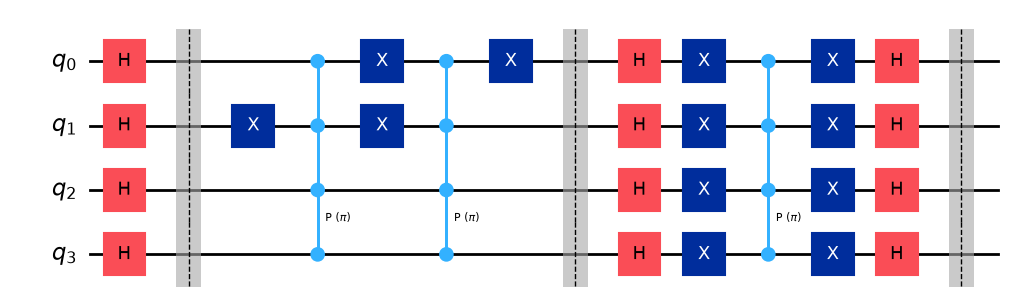

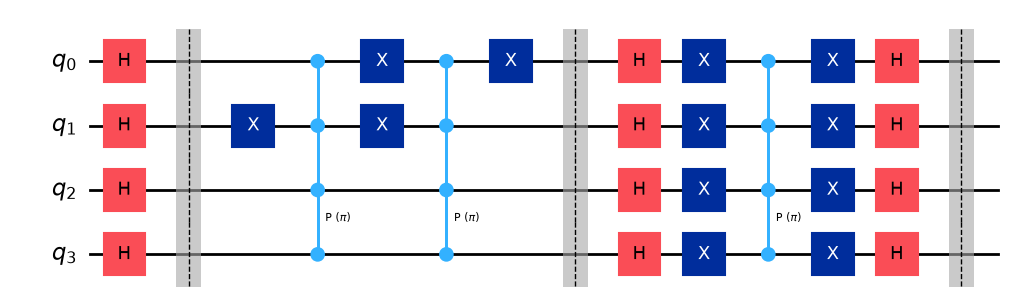

In [11]:
# This cell computes the quantities that fix the Grover search for this example and draws the
# circuit with one Grover iteration.

# The search space has N = 2^N_QUBITS = 16 states, of which |M| = 2 are marked. With
# sin(theta) = sqrt(|M| / N), each Grover iteration rotates the state by an angle 2*theta towards
# the marked states, and after k iterations the probability of measuring a marked pair is
# sin^2((2k + 1) theta) [1, 2]. The optimal number of iterations is the k that brings this
# probability closest to 1.

# Reading the circuit. The qubits q0..q3 hold the pair index, with q0 the least significant bit.
#   - Hadamard gates on all qubits prepare the uniform superposition |s> over the 16 indices.
#   - The oracle O_f follows, with one block per marked pair. Each block is a multi-controlled
#     phase gate P(pi) between X gates. For index 13 (binary 1101) the X gates act on q1, the only
#     0 bit. For index 14 (binary 1110) they act on q0. In the drawing, the X gate that closes the
#     first block and the X gate that opens the second block share one column.
#   - The diffusion D follows, with Hadamard gates, X gates on all qubits, the multi-controlled
#     phase gate P(pi) (sign flip of |0000>), X gates and Hadamard gates again.
# The grey vertical bands are barriers that only separate the parts of the circuit in the drawing.
# They have no effect on the computation.

N = 2 ** N_QUBITS
theta = math.asin(math.sqrt(len(M) / N))
k_opt = optimal_iterations(N, len(M))

print(f"N = {N} states, |M| = {len(M)} marked, theta = {theta:.4f} rad")
print(f"optimal number of iterations k = {k_opt}; predicted probability "
      f"sin^2((2k + 1) theta) = {math.sin((2 * k_opt + 1) * theta) ** 2:.3f}")

grover_circuit(M, 1).draw("mpl", fold=-1)

In [12]:
# Here is the central result of the example. The same circuit is run twice for k = 0, 1, ..., K_MAX
# Grover iterations, once with the oracle O_f and once with the oracle removed (diffusion only). In
# both runs the cell computes the exact probability of measuring a reducible pair.

K_MAX = 8

p_with_oracle = grover_trace(M, K_MAX)
p_without_oracle = grover_trace(M, K_MAX, use_oracle=False)
p_theory = [math.sin((2 * k + 1) * theta) ** 2 for k in range(K_MAX + 1)]

print(" k   with oracle   sin^2((2k+1)theta)   without oracle")
for k in range(K_MAX + 1):
    assert abs(p_with_oracle[k] - p_theory[k]) < 1e-9
    assert abs(p_without_oracle[k] - len(M) / N) < 1e-9
    print(f"{k:2d}   {p_with_oracle[k]:.3f}         {p_theory[k]:.3f}"
          f"                {p_without_oracle[k]:.3f}")

 k   with oracle   sin^2((2k+1)theta)   without oracle
 0   0.125         0.125                0.125
 1   0.781         0.781                0.125
 2   0.945         0.945                0.125
 3   0.330         0.330                0.125
 4   0.012         0.012                0.125
 5   0.548         0.548                0.125
 6   1.000         1.000                0.125
 7   0.577         0.577                0.125
 8   0.019         0.019                0.125


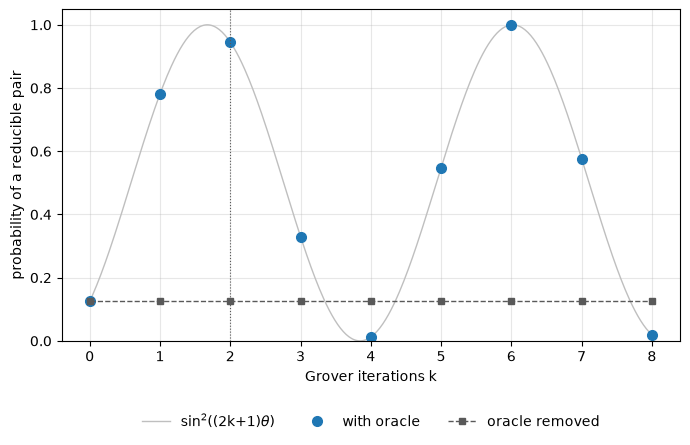

In [13]:
# With the oracle, the probability follows sin^2((2k + 1) theta). It rises from |M| / N = 0.125
# at k = 0 to 0.945 at the optimal k = 2, and then falls and rises again, because each further
# iteration keeps rotating the state by 2*theta past the marked states.

# Without the oracle, the probability stays at 0.125 for every k. The diffusion D maps the uniform
# superposition |s> to itself, so nothing changes. The whole increase is therefore produced by the
# oracle. The diffusion alone amplifies nothing.

# The previous cell also checks every simulated value against the formula sin^2((2k + 1) theta),
# and stops with an error if any differs.

# The plot shows the formula as a continuous grey curve, the simulated values with the oracle as
# blue circles, the values without the oracle as grey squares on a dashed line, and the optimal
# number of iterations as a dotted vertical line. Only whole numbers of iterations can be run, and
# the continuous curve between them only guides the eye. The legend is placed below the plot so that
# it hides no data point.

k_fine = np.linspace(0, K_MAX, 400)
plt.figure(figsize=(7, 4.6))
plt.plot(k_fine, np.sin((2 * k_fine + 1) * theta) ** 2, color="0.75", lw=1,
         label="sin$^2$((2k+1)$\\theta$)")
plt.plot(range(K_MAX + 1), p_with_oracle, "o", color="C0", ms=7,
         label="with oracle")
plt.plot(range(K_MAX + 1), p_without_oracle, "s--", color="0.35", ms=5, lw=1,
         label="oracle removed")
plt.axvline(k_opt, color="0.35", lw=0.8, ls=":")
plt.xlabel("Grover iterations k")
plt.ylabel("probability of a reducible pair")
plt.ylim(0, 1.05)
plt.xticks(range(K_MAX + 1))
plt.grid(alpha=0.3)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

In [14]:
# The previous cell computed exact probabilities from the state vector. A quantum computer does
# not give probabilities. Each run of the circuit ends with a measurement that returns one pair
# index. This cell imitates that. The circuit with k_opt = 2 Grover iterations, followed by a
# measurement of all qubits, is run SHOTS = 4096 times, and the outcomes are counted.

# The simulator is StatevectorSampler. It draws the measurement outcomes at random from the exact
# probabilities. Its random generator is started with SEED, so the counts below are reproducible.

# Reading the result. The fraction of shots that return a reducible pair estimates the probability
# 0.945 of the previous cell. With 4096 shots the statistical uncertainty of this estimate is about
# sqrt(0.945 * 0.055 / 4096) = 0.004, so the result is expected to lie within about 0.01 of 0.945.
# Qiskit reports each outcome as a bit string q3 q2 q1 q0, which read as a binary number is the pair
# index.

SHOTS = 4096

qc = grover_circuit(M, k_opt, measure=True)
result = StatevectorSampler(seed=SEED).run([qc], shots=SHOTS).result()
counts = result[0].data.meas.get_counts()

hits = sum(c for bits, c in counts.items() if int(bits, 2) in M)
print(f"{hits} of {SHOTS} shots ({hits / SHOTS:.3f}) return a reducible pair "
      f"(exact probability {p_with_oracle[k_opt]:.3f})")

print("\nmost frequent outcomes:")
for bits, c in sorted(counts.items(), key=lambda item: -item[1])[:4]:
    index = int(bits, 2)
    name = pair_label(index) if index < len(pairs) else "padding state"
    note = "   reducible" if index in M else ""
    print(f"  {bits} = index {index:2d} {name:14s} {c:5d} shots{note}")

3880 of 4096 shots (0.947) return a reducible pair (exact probability 0.945)

most frequent outcomes:
  1101 = index 13 (v4, v6)        1967 shots   reducible
  1110 = index 14 (v5, v6)        1913 shots   reducible
  0000 = index  0 (v1, v2)          20 shots
  1111 = index 15 padding state     19 shots


In [15]:
# For SEED = 20251006, 3880 of the 4096 shots (0.947) return a reducible pair,
# split almost equally between (v4, v6) and (v5, v6).


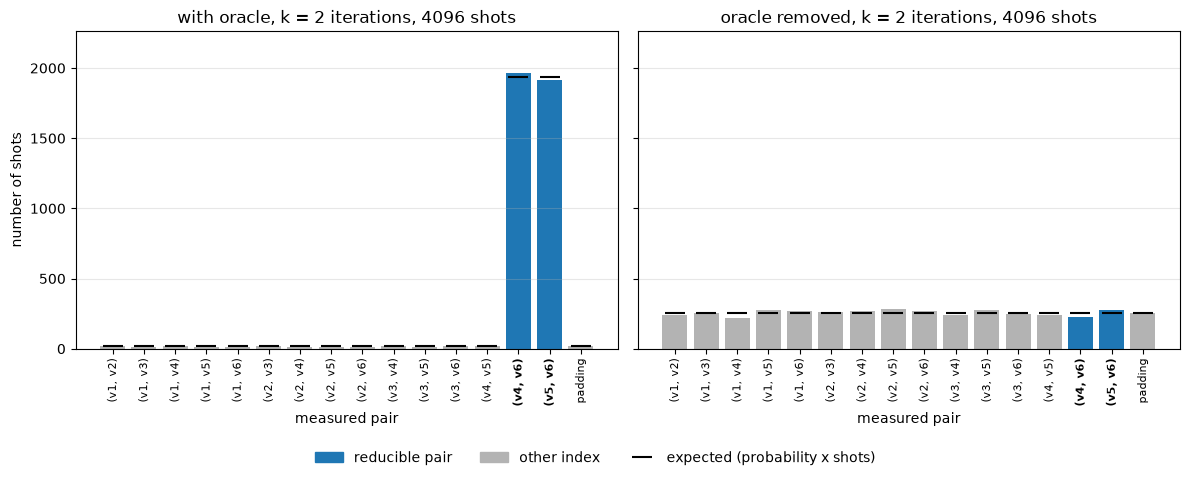

with oracle:    3880 of 4096 shots return a reducible pair
oracle removed: 507 of 4096 shots return a reducible pair


In [16]:
# This cell shows the counts of the previous cell as a bar chart, one bar per pair index,
# next to the counts of the same circuit with the oracle removed (k_opt = 2 iterations of
# diffusion only, also SHOTS = 4096 shots). Both panels use the same vertical scale.

# On the left (with oracle), almost all shots fall on the two reducible pairs, (v4, v6) and
# (v5, v6), and every other pair is measured only rarely.
# On the right (oracle removed), the shots are spread almost evenly over all 16 indices,
# about 4096 / 16 = 256 each, exactly as for a random guess. Without the oracle nothing
# distinguishes the reducible pairs.

# Reducible pairs are drawn in blue and their names are printed in bold on the horizontal axis.
# All other indices are grey. The black horizontal marks show the expected number of shots for
# each index, i.e. the exact probability times SHOTS. The bars differ from them only by the
# statistical fluctuation of sampling.

qc_without = grover_circuit(M, k_opt, use_oracle=False, measure=True)
result_without = StatevectorSampler(seed=SEED).run([qc_without], shots=SHOTS).result()
counts_without = result_without[0].data.meas.get_counts()

indices = np.arange(N)
labels = [pair_label(x) if x < len(pairs) else "padding" for x in indices]
colours = ["C0" if x in M else "0.7" for x in indices]

panels = [
    ("with oracle", counts,
     Statevector.from_instruction(grover_circuit(M, k_opt)).probabilities()),
    ("oracle removed", counts_without,
     Statevector.from_instruction(grover_circuit(M, k_opt, use_oracle=False)).probabilities()),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, (title, cts, probs) in zip(axes, panels):
    shots_per_index = [cts.get(format(x, f"0{N_QUBITS}b"), 0) for x in indices]
    ax.bar(indices, shots_per_index, color=colours, width=0.8)
    ax.plot(indices, probs * SHOTS, "_", color="black", ms=14, mew=1.5)
    ax.set_title(f"{title}, k = {k_opt} iterations, {SHOTS} shots")
    ax.set_xticks(indices)
    ax.set_xticklabels(labels, rotation=90, fontsize=8)
    for x in M:
        ax.get_xticklabels()[x].set_fontweight("bold")
    ax.set_xlabel("measured pair")
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("number of shots")
axes[0].set_ylim(0, 1.15 * max(max(counts.values()), max(counts_without.values())))
legend_items = [
    plt.Rectangle((0, 0), 1, 1, color="C0", label="reducible pair"),
    plt.Rectangle((0, 0), 1, 1, color="0.7", label="other index"),
    plt.Line2D([], [], color="black", marker="_", ls="none", ms=14, mew=1.5,
               label="expected (probability x shots)"),
]
fig.legend(handles=legend_items, loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

hits_without = sum(c for bits, c in counts_without.items() if int(bits, 2) in M)
print(f"with oracle:    {hits} of {SHOTS} shots return a reducible pair")
print(f"oracle removed: {hits_without} of {SHOTS} shots return a reducible pair")

In [17]:
# All previous cells use a simulator. This cell submits the circuit of Cell 14 (the circuit drawn
# in Cell 11, with k_opt = 2 Grover iterations instead of one, followed by a measurement) to a real
# IBM quantum computer.

# Load the needed libraries. The cell uses the Sampler of qiskit_ibm_runtime.executor_sampler,
# which replaces SamplerV2 (deprecated since qiskit-ibm-runtime 0.50.0) and is used in the same way.
# It requires qiskit-ibm-runtime 0.50.0 or later.
from getpass import getpass
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime.executor_sampler import Sampler

In [18]:
# To actually run on an IBM Quantum Computer, an IBM Quantum Platform account
# (quantum.cloud.ibm.com) and its API key (token), which is found in the account settings, are
# needed.

# This notebook accompanies a published paper and is meant to be shared, so the cell is
# written in a way that never puts an account token into the notebook, to avoid exposing
# someone's API key.
# If a token were written into a cell, it would be saved in the notebook file,
# and anyone who obtains a copy of the file could then use the account. To avoid that
# exposure, the cell asks for the token when it runs, in a hidden input field, uses it
# only to connect, and then deletes it from memory.
# IBM_INSTANCE may be set to the CRN of a specific instance of the account. If it is left as
# None, an available instance is selected.

# Readers without an IBM account can skip this cell. All results of the previous cells are
# unaffected.

# What the cell does. It connects to the account, picks the least busy real device, and translates
# the circuit into the gates and qubit connections of that device. This step is called
# transpilation, and its random choices are fixed with SEED. The cell then prints how many
# two-qubit gates the translated circuit contains, since these are the main source of errors on
# current hardware, runs SHOTS = 4096 shots and reports the outcomes in the same way as Cell 14.

IBM_INSTANCE = None     # optional CRN of an instance, e.g. "crn:v1:bluemix:..."

token = getpass("IBM Quantum API key (token): ")
service = QiskitRuntimeService(channel="ibm_quantum_platform", token=token,
                               instance=IBM_INSTANCE)
del token                # the token is not kept in the notebook's memory

backend = service.least_busy(operational=True, simulator=False)

qc_hw = grover_circuit(M, k_opt, measure=True)
pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=3,
                                            seed_transpiler=SEED)
qc_transpiled = pass_manager.run(qc_hw)
two_qubit_gates = sum(1 for instruction in qc_transpiled.data
                      if instruction.operation.num_qubits == 2)
print(f"device: {backend.name}; two-qubit gates after transpilation: "
      f"{two_qubit_gates}")

job = Sampler(mode=backend).run([qc_transpiled], shots=SHOTS)

print(f"job id: {job.job_id()} (waiting for the result ...)")
counts_hw = job.result()[0].data.meas.get_counts()

hits_hw = sum(c for bits, c in counts_hw.items() if int(bits, 2) in M)
print(f"\n{hits_hw} of {SHOTS} shots ({hits_hw / SHOTS:.3f}) return a "
      f"reducible pair (simulator: {hits / SHOTS:.3f}; "
      f"random guess: {len(M) / N:.3f})")
print("\nmost frequent outcomes:")
for bits, c in sorted(counts_hw.items(), key=lambda item: -item[1])[:4]:
    index = int(bits, 2)
    name = pair_label(index) if index < len(pairs) else "padding state"
    note = "   reducible" if index in M else ""
    print(f"  {bits} = index {index:2d} {name:14s} {c:5d} shots{note}")

IBM Quantum API key (token):  ········


qiskit_runtime_service._discover_account:WARNING:2026-11-10 23:39:49,218: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-10 23:39:52,962: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-10 23:39:53,443: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-10 23:39:55,910: Using instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-10 23:39:56,

device: ibm_fez; two-qubit gates after transpilation: 179
job id: dbpoucc4148s739uvl10 (waiting for the result ...)

1840 of 4096 shots (0.449) return a reducible pair (simulator: 0.947; random guess: 0.125)

most frequent outcomes:
  1110 = index 14 (v5, v6)         980 shots   reducible
  1101 = index 13 (v4, v6)         860 shots   reducible
  1111 = index 15 padding state    203 shots
  0101 = index  5 (v2, v3)         182 shots


In [19]:
# Reading the result. Hardware noise lowers the fraction of shots that return a reducible pair below
# the ideal 0.947 of the simulator. How much depends on the device and on the day. Two reference
# values help to read it. A random guess returns a reducible pair with probability
# |M| / N = 2 / 16 = 0.125, and in the ideal circuit every other index has probability below 0.01.
# As long as the fraction stays clearly above 0.125 and the two reducible pairs remain the most
# frequent outcomes, the oracle-driven amplification survives the noise.

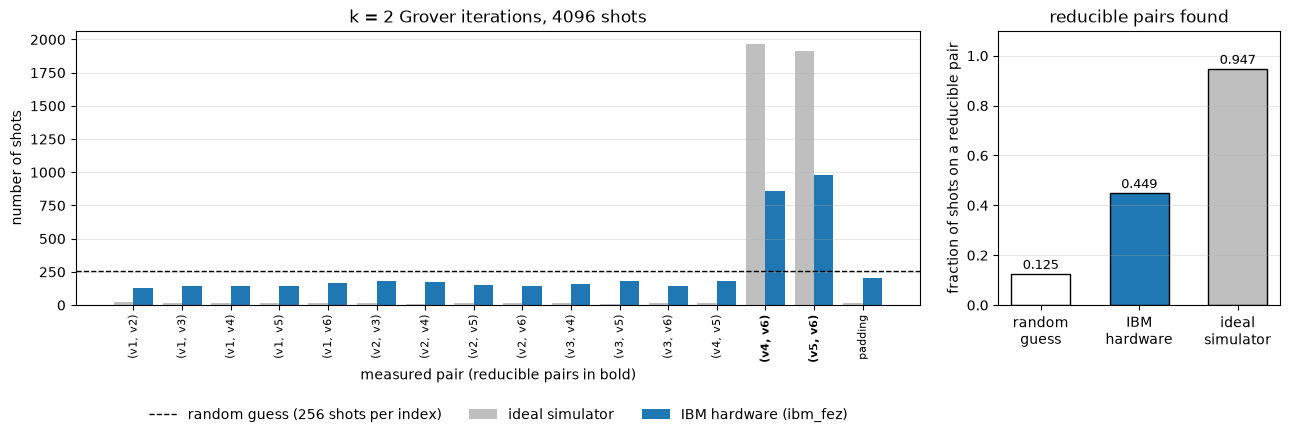

In [20]:
# This cell shows the counts of the previous cell (IBM hardware) next to the counts of the ideal
# simulator for the same circuit (Cell 14), both with k_opt = 2 Grover iterations and
# SHOTS = 4096 shots. It needs the results of both cells, so it runs only after the hardware cell.

# The left panel shows the number of shots for each of the 16 pair indices, with simulator and
# hardware side by side. The reducible pairs are printed in bold on the horizontal axis. The dashed
# line is the random guess, SHOTS / N = 256 shots for every index.
# The right panel shows the fraction of the shots that return a reducible pair, for a random guess
# (|M| / N = 0.125), for the hardware and for the ideal simulator.

indices = np.arange(N)
labels = [pair_label(x) if x < len(pairs) else "padding" for x in indices]
shots_simulator = [counts.get(format(x, f"0{N_QUBITS}b"), 0) for x in indices]
shots_hardware = [counts_hw.get(format(x, f"0{N_QUBITS}b"), 0) for x in indices]

fig, (ax_left, ax_right) = plt.subplots(
    1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [3, 1]})

width = 0.4
ax_left.bar(indices - width / 2, shots_simulator, width, color="0.75",
            label="ideal simulator")
ax_left.bar(indices + width / 2, shots_hardware, width, color="C0",
            label=f"IBM hardware ({backend.name})")
ax_left.axhline(SHOTS / N, color="black", ls="--", lw=1,
                label=f"random guess ({SHOTS // N} shots per index)")
ax_left.set_xticks(indices)
ax_left.set_xticklabels(labels, rotation=90, fontsize=8)
for x in M:
    ax_left.get_xticklabels()[x].set_fontweight("bold")
ax_left.set_xlabel("measured pair (reducible pairs in bold)")
ax_left.set_ylabel("number of shots")
ax_left.set_title(f"k = {k_opt} Grover iterations, {SHOTS} shots")
ax_left.grid(axis="y", alpha=0.3)
ax_left.legend(loc="upper center", bbox_to_anchor=(0.5, -0.33), ncol=3,
               frameon=False)

fractions = [len(M) / N, hits_hw / SHOTS, hits / SHOTS]
names = ["random\nguess", "IBM\nhardware", "ideal\nsimulator"]
bars = ax_right.bar(names, fractions, color=["white", "C0", "0.75"],
                    edgecolor="black", width=0.6)
for bar, value in zip(bars, fractions):
    ax_right.text(bar.get_x() + bar.get_width() / 2, value + 0.02,
                  f"{value:.3f}", ha="center", fontsize=9)
ax_right.set_ylim(0, 1.1)
ax_right.set_ylabel("fraction of shots on a reducible pair")
ax_right.set_title("reducible pairs found")
ax_right.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
# Reading the result. Hardware noise moves some shots from the reducible pairs to the other indices,
# so the hardware bars of the reducible pairs are lower than those of the simulator and the other
# bars are higher. The oracle-driven amplification survives the noise as long as the reducible pairs
# remain clearly above the dashed line and the hardware fraction on the right remains clearly above
# the random guess.